# NGL transfer: Adapazari and Christchurch

Evaluate the internally fitted models on the two natural-soil laboratory
collections. Pressure targets use a cyclic-pressure correction. Event rules and
scoring denominators follow the source-specific protocol.

In [1]:
from pathlib import Path
import sys
import os
from datetime import datetime, timezone
os.environ.setdefault("LIQ_FINAL_DEVICE", os.environ.get("LIQ_DEVICE", "cpu"))
os.environ.setdefault("LIQ_DEVICE", os.environ["LIQ_FINAL_DEVICE"])
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/dpi_evt").is_dir())
for directory in (ROOT / "src", ROOT / "external_validation", ROOT / "scripts"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": .2})
COLORS = {"DPI-EVT":"#246aac", "DPI-EVT +A":"#1b9e8a", "EVT-NeuralSSM":"#69788a",
          "Transformer +cummax":"#c17a24", "Transformer matched +A/crossing loss":"#8658a6",
          "GP prefix (linear + SE)":"#8469a5", "Threshold-projected Transformer/GBM":"#777777",
          "Time-warped Transformer/GBM":"#b685b3", "GBM horizon mixture":"#a66c20", "Cox PH":"#555555"}
TABLES = ROOT / "results/tables"
print("Executed:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("Inputs: included aggregate tables and public external extracts")

Executed: 2026-11-06T14:07:04+00:00
Inputs: included aggregate tables and public external extracts


## Joint forecast transfer

,source,model,tests,curve_tests,events,curve_rmse,onset_logmae
0,Adapazari,Cox PH,54,0,46,NaN,0.6152
2,Adapazari,DPI-EVT +A,54,53,46,0.2897,0.5812
3,Adapazari,DPI-EVT +A/no reciprocal drift,54,53,46,0.2738,0.7609
7,Adapazari,GBM horizon mixture,54,0,46,NaN,0.5322
12,Adapazari,Threshold-projected Transformer/GBM,54,53,46,0.3040,0.5322
19,Adapazari,Transformer matched +A/crossing loss,54,53,46,0.3166,1.0313
22,Christchurch,Cox PH,21,0,15,NaN,0.3125
24,Christchurch,DPI-EVT +A,21,20,15,0.1870,0.5342
25,Christchurch,DPI-EVT +A/no reciprocal drift,21,20,15,0.2028,0.9041
29,Christchurch,GBM horizon mixture,21,0,15,NaN,0.3578


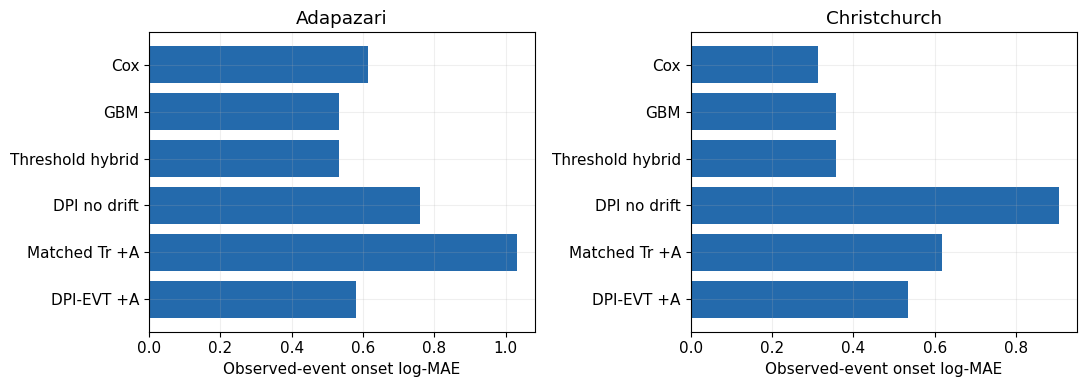

In [2]:
joint=pd.read_csv(TABLES/"joint_metrics.csv")
models=["DPI-EVT +A","Transformer matched +A/crossing loss","DPI-EVT +A/no reciprocal drift",
        "Threshold-projected Transformer/GBM","GBM horizon mixture","Cox PH"]
d=joint[joint.source.isin(["Adapazari","Christchurch"]) & joint.model.isin(models)]
display(d[["source","model","tests","curve_tests","events","curve_rmse","onset_logmae"]].round(4))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,(source,g) in zip(axes,d.groupby("source")):
    g=g.set_index("model").reindex(models)
    short=["DPI-EVT +A","Matched Tr +A","DPI no drift","Threshold hybrid","GBM","Cox"]
    ax.barh(short,g.onset_logmae,color="#246aac")
    ax.set(xlabel="Observed-event onset log-MAE",title=source)
fig.tight_layout();plt.show()

## Transferred residual interval coverage

In [3]:
z=pd.read_csv(TABLES/"interval_external.csv")
z=z[z.source.isin(["Adapazari","Christchurch"]) & z.method.eq("validation_log_asymmetric") & np.isclose(z.target,.9)]
display(z[["source","model","coverage","mean_width_H"]].round(4))

,source,model,coverage,mean_width_H
5,Adapazari,cox_ph,0.5652,35.9511
6,Christchurch,cox_ph,0.8444,32.0208
20,Adapazari,dpi_evt,0.7304,81.9272
21,Christchurch,dpi_evt,0.8222,77.4229
35,Adapazari,dpi_evt_A,0.7043,56.2545
36,Christchurch,dpi_evt_A,0.8578,51.1962
50,Adapazari,dpi_evt_AC,0.7696,57.8074
51,Christchurch,dpi_evt_AC,0.9422,54.8064
65,Adapazari,dpi_evt_C,0.7449,79.5651
66,Christchurch,dpi_evt_C,0.8667,69.9213


## Interpretation

Mechanical-property imputers use the corresponding internal training fold. Missing grain-size curves use the external source median before quality filtering. The external collections have no known by-horizon non-events, so they do not establish two-class external event discrimination. Pressure continuation uses 53 Adapazari and 20 Christchurch tests; timing includes 46 and 15 observed events.